# Predicción de abandono de tarjetahabientes

**Pregunta de negocio:** ¿qué clientes de tarjeta de crédito están por cancelar el producto, y por qué? Detectarlos a tiempo permite ofrecerles una acción de retención antes de perderlos.

**Datos:** [Credit Card Customers (Kaggle)](https://www.kaggle.com/datasets/sakshigoyal7/credit-card-customers), perfil y uso de ~10.000 clientes. Licencia CC0.

**Contenido**
1. Carga de datos
2. Exploración
3. Modelos y elección del umbral
4. ¿Qué anticipa el abandono? (importancia de variables)
5. Lista de clientes en riesgo y valor en riesgo

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_recall_curve,
                             ConfusionMatrixDisplay, classification_report)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

PALETA = ["#6B2D8C", "#7A1F3D", "#B23A6A", "#D9C2E8", "#3E2447"]
sns.set_theme(style="whitegrid", palette=PALETA)
RANDOM_STATE = 42

DATA_DIR = Path("data/raw")
OUT_DIR = Path("outputs")
DATA_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

## 1. Carga de datos
Kaggle pide iniciar sesión para descargar. Descarga el archivo desde la página del dataset y coloca `BankChurners.csv` en `data/raw/`.

Alternativa con la API de Kaggle: `kaggle datasets download -d sakshigoyal7/credit-card-customers -p data/raw --unzip`

In [4]:
CSV = DATA_DIR / "BankChurners.csv"
if not CSV.exists():
    raise FileNotFoundError(
        "No se encontró data/raw/BankChurners.csv. Descárgalo de "
        "https://www.kaggle.com/datasets/sakshigoyal7/credit-card-customers"
    )

df = pd.read_csv(CSV)
df = df.drop(columns=[c for c in df.columns if c.startswith("Naive_Bayes")])
print(df.shape)
df.head()

(10127, 21)


,CLIENTNUM,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,...,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio
0,768805383,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,...,1,3,12691.0,777,11914.0,1.335,1144,42,1.625,0.061
1,818770008,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,...,1,2,8256.0,864,7392.0,1.541,1291,33,3.714,0.105
2,713982108,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,...,1,0,3418.0,0,3418.0,2.594,1887,20,2.333,0.000
3,769911858,Existing Customer,40,F,4,High School,Unknown,Less than $40K,Blue,34,...,4,1,3313.0,2517,796.0,1.405,1171,20,2.333,0.760
4,709106358,Existing Customer,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,...,1,0,4716.0,0,4716.0,2.175,816,28,2.500,0.000


## 2. Exploración

Tasa de abandono: 16.1%


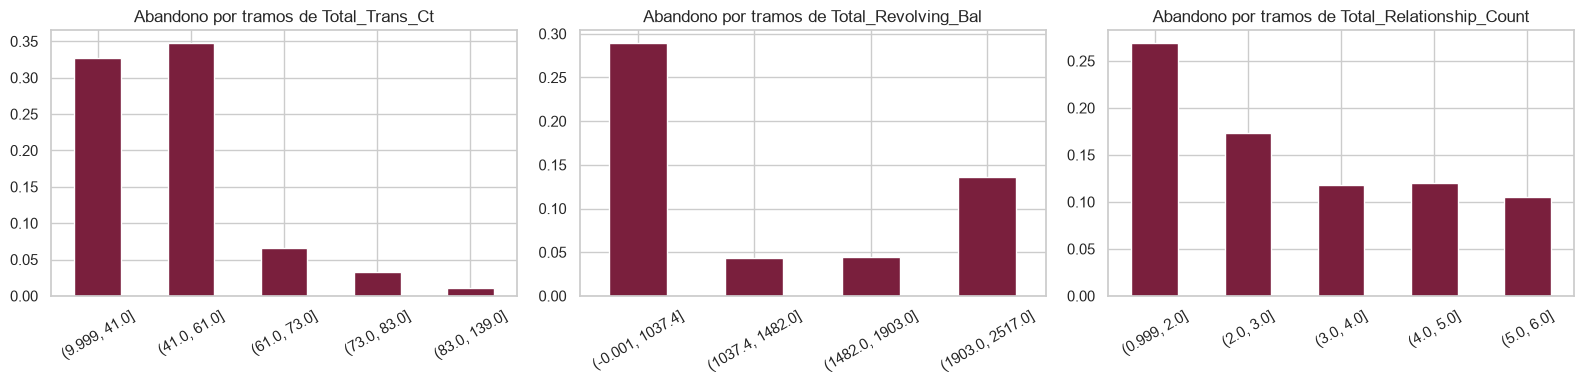

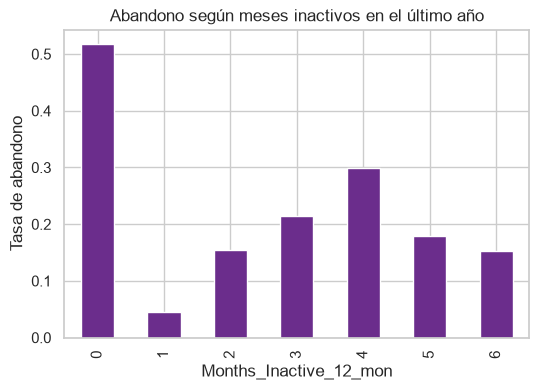

In [5]:
df["abandono"] = (df["Attrition_Flag"] == "Attrited Customer").astype(int)
print(f"Tasa de abandono: {df['abandono'].mean():.1%}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["Total_Trans_Ct", "Total_Revolving_Bal", "Total_Relationship_Count"]):
    tramos = pd.qcut(df[col], 5, duplicates="drop")
    df.groupby(tramos, observed=True)["abandono"].mean().plot.bar(ax=ax, color=PALETA[1])
    ax.set_title(f"Abandono por tramos de {col}")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 4))
df.groupby("Months_Inactive_12_mon")["abandono"].mean().plot.bar(ax=ax, color=PALETA[0])
ax.set_title("Abandono según meses inactivos en el último año")
ax.set_ylabel("Tasa de abandono")
plt.show()

**Lectura:** quienes hacen pocas transacciones, no mantienen saldo rotativo y tienen pocos productos con el banco abandonan mucho más. La inactividad es una alerta temprana.

## 3. Modelos y elección del umbral

In [6]:
y = df["abandono"]
X = df.drop(columns=["abandono", "Attrition_Flag", "CLIENTNUM"])
cat_cols = X.select_dtypes("object").columns.tolist()
num_cols = X.select_dtypes("number").columns.tolist()

X_train, X_test, y_train, y_test, id_train, id_test = train_test_split(
    X, y, df["CLIENTNUM"], test_size=0.25, stratify=y, random_state=RANDOM_STATE
)

preprocesador = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
])

modelos = {
    "Regresión logística": LogisticRegression(max_iter=3000, class_weight="balanced"),
    "Gradient boosting": HistGradientBoostingClassifier(
        learning_rate=0.05, max_iter=400, random_state=RANDOM_STATE
    ),
}

entrenados, resultados = {}, []
for nombre, modelo in modelos.items():
    pipe = Pipeline([("pre", clone(preprocesador)), ("modelo", modelo)])
    pipe.fit(X_train, y_train)
    p = pipe.predict_proba(X_test)[:, 1]
    entrenados[nombre] = pipe
    resultados.append({"Modelo": nombre, "ROC AUC": roc_auc_score(y_test, p),
                       "PR AUC": average_precision_score(y_test, p)})

resultados = pd.DataFrame(resultados).set_index("Modelo").round(3)
resultados

,ROC AUC,PR AUC
Modelo,,
Regresión logística,0.919,0.730
Gradient boosting,0.994,0.969


El umbral por defecto (0,5) no siempre es el mejor. Elegimos el que maximiza el F1, un equilibrio entre no molestar a clientes que no se iban (precisión) y no dejar escapar a los que sí (recall).

Modelo elegido: Gradient boosting | umbral: 0.21
              precision    recall  f1-score   support

    Se queda       0.98      0.98      0.98      2125
    Abandona       0.91      0.92      0.91       407

    accuracy                           0.97      2532
   macro avg       0.95      0.95      0.95      2532
weighted avg       0.97      0.97      0.97      2532



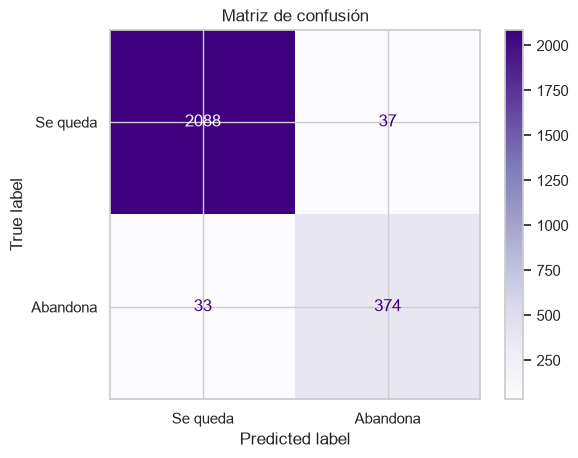

In [7]:
mejor_nombre = resultados["PR AUC"].idxmax()
mejor = entrenados[mejor_nombre]
prob = mejor.predict_proba(X_test)[:, 1]

precision, recall, umbrales = precision_recall_curve(y_test, prob)
f1 = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-9)
umbral = float(umbrales[np.argmax(f1)])
pred = (prob >= umbral).astype(int)

print(f"Modelo elegido: {mejor_nombre} | umbral: {umbral:.2f}")
print(classification_report(y_test, pred, target_names=["Se queda", "Abandona"]))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Se queda", "Abandona"], cmap="Purples")
plt.title("Matriz de confusión")
plt.show()

## 4. ¿Qué anticipa el abandono?
Usamos **importancia por permutación**: cuánto empeora el modelo si desordenamos cada variable.

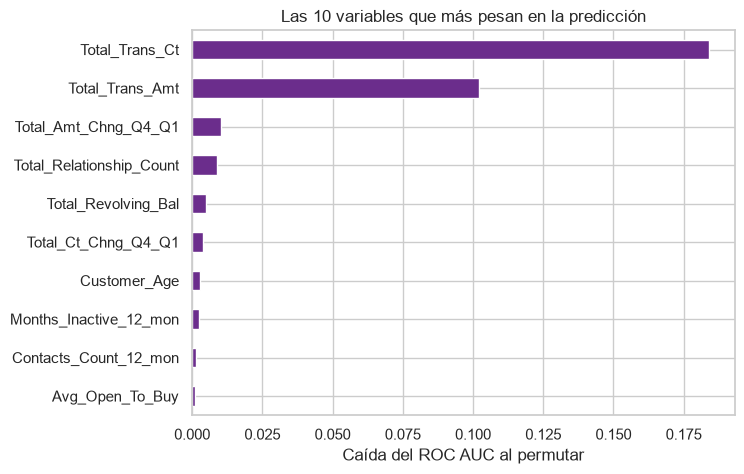

In [8]:
imp = permutation_importance(mejor, X_test, y_test, scoring="roc_auc", n_repeats=5,
                             random_state=RANDOM_STATE, n_jobs=-1)
importancia = pd.Series(imp.importances_mean, index=X_test.columns).sort_values(ascending=False).head(10)

fig, ax = plt.subplots(figsize=(7, 5))
importancia.sort_values().plot.barh(ax=ax, color=PALETA[0])
ax.set_title("Las 10 variables que más pesan en la predicción")
ax.set_xlabel("Caída del ROC AUC al permutar")
plt.show()

## 5. Clientes en riesgo y valor en riesgo
Priorizamos a los clientes que el modelo marca como riesgo según cuánto transaccionan, para enfocar la retención donde más valor hay.

In [9]:
riesgo = X_test.copy()
riesgo.insert(0, "CLIENTNUM", id_test.values)
riesgo["prob_abandono"] = prob
riesgo["abandono_real"] = y_test.values
en_riesgo = riesgo[riesgo["prob_abandono"] >= umbral].sort_values(
    ["Total_Trans_Amt", "prob_abandono"], ascending=False
)

valor_en_riesgo = en_riesgo["Total_Trans_Amt"].sum()
print(f"Clientes marcados en riesgo: {len(en_riesgo):,} de {len(riesgo):,}")
print(f"Monto transaccionado anual de esos clientes: {valor_en_riesgo:,.0f}")

en_riesgo.to_csv(OUT_DIR / "clientes_en_riesgo.csv", index=False)
en_riesgo[["CLIENTNUM", "prob_abandono", "Total_Trans_Amt", "Total_Trans_Ct", "Months_Inactive_12_mon"]].head(10)

Clientes marcados en riesgo: 411 de 2,532
Monto transaccionado anual de esos clientes: 1,284,019


,CLIENTNUM,prob_abandono,Total_Trans_Amt,Total_Trans_Ct,Months_Inactive_12_mon
10118,713755458,0.995088,10310,63,3
10124,716506083,0.999191,10291,60,3
9458,710155158,0.999844,10201,59,1
9968,759584958,0.999723,10156,72,2
9975,712627083,0.999904,9867,78,2
9756,708385533,0.996054,9524,80,3
9823,713347608,0.999856,9442,69,3
10006,714524583,0.953428,9441,82,3
10112,708564858,0.994170,9338,73,1
9285,714615258,0.980770,9330,64,3


## Conclusiones
- El modelo detecta la mayoría de los abandonos con buena precisión, lo que hace viable una campaña de retención enfocada.
- Las señales más fuertes son de comportamiento (número y monto de transacciones, saldo rotativo, inactividad), no demográficas: se pueden monitorear mes a mes.
- Acción sugerida: alerta automática cuando un cliente cae en el umbral, con oferta según su nivel de uso.